# Лекция 5. Учим саму стратегию: градиент стратегии и REINFORCE

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/IlyaChichkanov/Reinforcement-learning/blob/main/05-policy-gradient/lecture/lecture.ipynb)

**Главный вопрос сегодня: как учить вероятности действий напрямую — и зачем, если Q-learning уже работает?**

Карта пути. Лекции 3 и 4 учили таблицу ценностей $Q$, а стратегию получали из неё: в каждом состоянии — действие с наибольшим $Q$. Сегодня идём другим путём, который мы уже видели в лекции 1: Cross-Entropy учил **саму стратегию** (policy) — вероятности действий — по сыгранным эпизодам. Сначала посмотрим на среду, где лучшая стратегия стохастическая, а таблица ценностей такую стратегию не даёт. Потом научимся сдвигать вероятности по наклону среднего выигрыша (это и есть **градиент стратегии**) и соберём из этого алгоритм REINFORCE. В конце разберём, почему из наград полезно вычитать среднее.

Лекция устроена как прошлая: раздел начинается с вопроса, на который мы **голосуем всей аудиторией**, и только потом проверяем ответ запуском. Вопросы и песочница — на странице-спутнике, откройте её на телефоне:

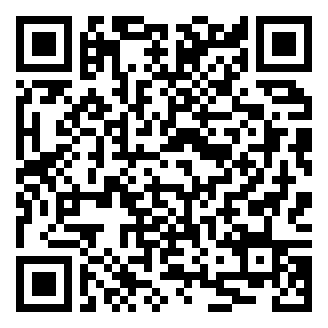

[ilyachichkanov.github.io/Reinforcement-learning/lecture05.html](https://ilyachichkanov.github.io/Reinforcement-learning/lecture05.html)

| | Раздел | Минут |
|---|---|---|
| 1 | 🔁 Ценности или вероятности: две семьи методов | 8 |
| 2 | Новая среда: коридор, где лучшая стратегия стохастическая | 14 |
| 3 | Стратегия с параметрами: softmax | 12 |
| 4 | REINFORCE: градиент стратегии по сыгранным эпизодам | 24 |
| 5 | Вычитаем среднее | 18 |
| 6 | ⏱ Value-based или policy-based | 7 |
| 7 | Итоги и где это работает | 7 |

Пометки: **🔁** — вспоминаем пройденное, **⏱** — резерв, если останется время. Служебный код лежит в `pg_plots.py`: среда-коридор, точный расчёт ценности и рисовальщики; читать его не нужно.

In [1]:
# Служебный модуль лекции. Локально он уже в репозитории, в Google Colab — скачивается.
import pathlib, urllib.request
REPO = "https://raw.githubusercontent.com/IlyaChichkanov/Reinforcement-learning/main/"
if not pathlib.Path("pg_plots.py").exists():
    urllib.request.urlretrieve(REPO + "05-policy-gradient/lecture/pg_plots.py", "pg_plots.py")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pg_plots import *     # Corridor, corridor_value, corridor_slope, softmax, BANDIT_MEANS и рисовальщики

## 1. 🔁 Ценности или вероятности: две семьи методов

Вспомним два метода, которые уже были в курсе.

* **Q-learning** (лекции 3 и 4) хранит таблицу оценок $Q(s, a)$. После обучения агент ходит по ней так же, как в домашке 2 при **проверке по таблице**: в каждом состоянии делает действие с наибольшим $Q$.
* **Cross-Entropy** (лекция 1) хранит сами **вероятности действий** $\pi(a \mid s)$ — частоты действий в элитных эпизодах — и выбирает действие по этим вероятностям.

**Вопрос 1 (голосуем).** Оба метода обучены, и агент 100 раз оказывается в одной и той же клетке. У Q-learning строка таблицы в этой клетке: $Q(\leftarrow) = +0.10$, $Q(\downarrow) = -1.00$, $Q(\rightarrow) = +0.20$, $Q(\uparrow) = +0.40$. У Cross-Entropy вероятности действий в этой клетке: $\pi(\leftarrow) = 0.1$, $\pi(\downarrow) = 0.2$, $\pi(\rightarrow) = 0.3$, $\pi(\uparrow) = 0.4$. Что верно?

* **A.** по Q-learning он все 100 раз делает одно и то же действие, по Cross-Entropy — разные действия;
* **B.** наоборот: по Q-learning — разные действия, по Cross-Entropy — одно и то же;
* **C.** оба метода все 100 раз делают одно и то же действие;
* **D.** оба метода выбирают действия случайно.

Проверим: сыграем по каждой строке 100 раз и посчитаем, сколько раз выпало каждое действие.

Q-learning, 100 раз:    ←   0  ↓   0  →   0  ↑ 100
Cross-Entropy, 100 раз: ←  10  ↓  15  →  26  ↑  49


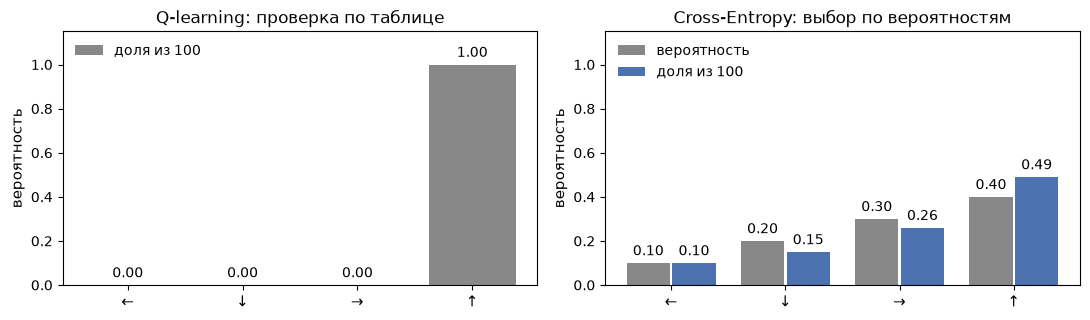

In [3]:
arrows = ["←", "↓", "→", "↑"]
q_row = np.array([+0.10, -1.00, +0.20, +0.40])    # Q-learning: строка таблицы Q из вопроса
pi_row = np.array([0.1, 0.2, 0.3, 0.4])            # Cross-Entropy: вероятности действий из вопроса

rng = np.random.default_rng(0)
by_table = np.full(100, q_row.argmax())                 # проверка по таблице: каждый раз действие с наибольшим Q
by_probs = rng.choice(4, size=100, p=pi_row)             # Cross-Entropy: каждый раз случайно по вероятностям
count_table, count_probs = np.bincount(by_table, minlength=4), np.bincount(by_probs, minlength=4)
print("Q-learning, 100 раз:   ", "  ".join(f"{a} {n:3d}" for a, n in zip(arrows, count_table)))
print("Cross-Entropy, 100 раз:", "  ".join(f"{a} {n:3d}" for a, n in zip(arrows, count_probs)))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
plot_probs({"доля из 100": count_table / 100}, ax=axes[0], labels=arrows, ylim=(0, 1.15),
           title="Q-learning: проверка по таблице")
plot_probs({"вероятность": pi_row, "доля из 100": count_probs / 100}, ax=axes[1], labels=arrows, ylim=(0, 1.15),
           title="Cross-Entropy: выбор по вероятностям")
plt.tight_layout(); plt.show()

Ответ **A**. По таблице Q-learning агент все 100 раз шагнул $\uparrow$ — у этого действия наибольшее $Q$. По вероятностям Cross-Entropy выпадали все четыре действия, с долями, близкими к 0.1 / 0.2 / 0.3 / 0.4. Это два вида стратегий из лекций 1 и 3:

* **детерминированная** — в одном и том же состоянии всегда одно и то же действие; в таблице стратегии в каждой строке одна единица. Так ходит Q-learning по таблице;
* **стохастическая** — действие выбирается случайно по вероятностям $\pi(a \mid s)$. Так ходит Cross-Entropy.

Отсюда две семьи методов:

* **value-based** (Q-learning, SARSA) учат ценности, а стратегия получается из них выбором действия с наибольшей ценностью — она детерминированная;
* **policy-based** учат вероятности действий напрямую — стратегия стохастическая. Cross-Entropy — первый наш пример, сегодня будет второй, главный.

На обрыве и в такси детерминированной стратегии хватало: лучшая стратегия там и была детерминированной. Следующий раздел — среда, где лучшая стратегия стохастическая.

**Одной строкой:** value-based учат ценности и выбирают действие с наибольшей — стратегия детерминированная; policy-based учат вероятности действий — стратегия стохастическая.

## 2. Новая среда: коридор, где лучшая стратегия стохастическая

Во всех средах прошлых лекций агент знал, в какой он клетке. Так бывает не всегда: датчики видят не всё, и два разных места выглядят одинаково — как одинаковые двери в длинном коридоре для робота с камерой. Возьмём самую маленькую среду с такой трудностью — коридор из учебника Саттона и Барто (пример 13.1).

Описание по чек-листу:

* **состояние** — клетка 0, 1 или 2; старт в клетке 0, выход справа от клетки 2;
* **наблюдение** — одно и то же во всех клетках: датчик агента клеток не различает;
* **действия** — два: ← и →; в клетке 1 они **перепутаны**: → ведёт в клетку 0, ← — в клетку 2; ← из клетки 0 упирается в стену, агент остаётся на месте;
* **награда** — $-1$ за каждый шаг, $\gamma = 1$: ценность старта — это минус среднее число шагов до выхода;
* **конец эпизода** — выход.

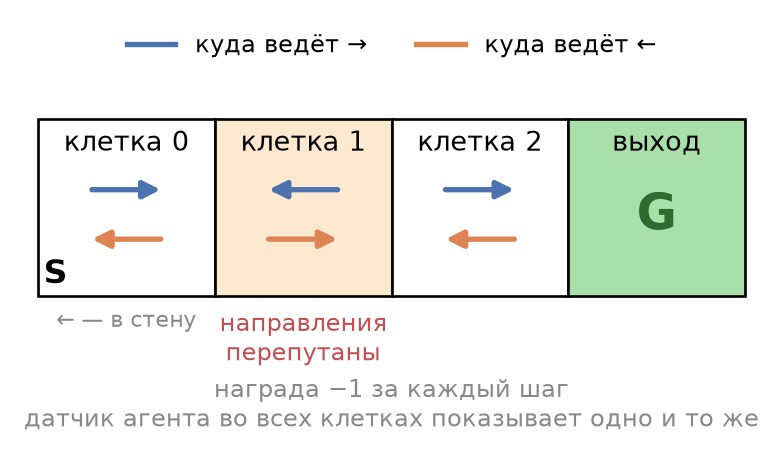

Раз наблюдение одно, стратегия агента — одно число: $p$ — **вероятность выбрать →**, одна и та же во всех клетках.

**Вопрос 2 (голосуем).** Какая стратегия в среднем доходит до выхода быстрее всех?

* **A.** всегда → ($p = 1$);
* **B.** $\varepsilon$-жадная с лучшим действием →, $\varepsilon = 0.1$ ($p = 0.95$);
* **C.** → и ← поровну ($p = 0.5$);
* **D.** всегда ← ($p = 0$).

Откуда 0.95 в варианте B: $\varepsilon$-жадная стратегия с вероятностью $1 - \varepsilon = 0.9$ делает лучшее действие →, а с вероятностью $\varepsilon = 0.1$ — случайное действие из двух, и → выпадает в половине таких случаев: $p = 0.9 + 0.1 \cdot 0.5 = 0.95$. У $\varepsilon$-жадной стратегии с лучшим действием ← так же $p = 0.1 \cdot 0.5 = 0.05$.

Сначала посмотрим на один эпизод при $p = 0.5$: что происходит на самом деле и что видит агент.

In [4]:
env = Corridor()
rng = np.random.default_rng(1)
obs, info = env.reset()
cells, observations = [info["cell"]], [obs]
while True:
    obs, r, terminated, truncated, info = env.step(int(rng.random() < 0.5))   # 1 = →, 0 = ←
    cells.append(info["cell"]); observations.append(obs)
    if terminated:
        break
print("клетка на самом деле:", *cells)
print("что видит агент:     ", *observations)
print(f"шагов: {len(cells) - 1}, return: {-(len(cells) - 1)}")

клетка на самом деле: 0 0 0 1 2 3
что видит агент:      0 0 0 0 0 0
шагов: 5, return: -5


Агент видит одни нули — по наблюдению нельзя понять, где он. Теперь посчитаем ценность каждой стратегии **точно** — уравнением Беллмана для стратегии из лекции 2:

$$
V^\pi(s) \;=\; \sum_a \pi(a \mid s) \sum_{s'} P(s' \mid s, a)\,\big[\, r + \gamma\, V^\pi(s') \,\big] .
$$

Напомним обозначения: $s$ — состояние, $a$ — действие, $s'$ — следующее состояние, $\pi(a \mid s)$ — вероятность, что стратегия выберет $a$ в $s$, $P(s' \mid s, a)$ — вероятность, что после $a$ среда переведёт агента из $s$ в $s'$, $r$ — награда за этот шаг, $\gamma$ — коэффициент дисконтирования. В лекции 2 вероятность перехода писалась маленькой $p$; здесь пишем заглавную $P$, чтобы не путать её с нашим $p$ — вероятностью выбрать →.

Подставим в уравнение коридор:

* состояние $s$ — номер клетки: 0, 1 или 2;
* переходы не случайные: действие из клетки $s$ всегда ведёт в одну и ту же клетку, поэтому $P(s' \mid s, a) = 1$ для неё и 0 для остальных, и сумма по $s'$ превращается в одно слагаемое;
* награда за любой шаг $r = -1$, $\gamma = 1$;
* $\pi(\rightarrow \mid s) = p$ и $\pi(\leftarrow \mid s) = 1 - p$ во всех клетках.

Получается $V(s) = p\,\big[-1 + V(\text{куда ведёт } \rightarrow \text{ из } s)\big] + (1 - p)\,\big[-1 + V(\text{куда ведёт } \leftarrow \text{ из } s)\big]$, то есть

$$
V(s) \;=\; -1 \;+\; p \cdot V(\text{куда ведёт } \rightarrow \text{ из } s) \;+\; (1 - p) \cdot V(\text{куда ведёт } \leftarrow \text{ из } s) .
$$

Выпишем его для каждой клетки $s = 0, 1, 2$, глядя на картинку коридора; у выхода $V = 0$:

$$
\begin{aligned}
V(0) &= -1 + p \cdot V(1) + (1 - p) \cdot V(0) && \rightarrow \text{ — в клетку 1, } \leftarrow \text{ — в стену, агент остаётся в 0} \\
V(1) &= -1 + p \cdot V(0) + (1 - p) \cdot V(2) && \text{направления перепутаны: } \rightarrow \text{ — в 0, } \leftarrow \text{ — в 2} \\
V(2) &= -1 + p \cdot 0 + (1 - p) \cdot V(1) && \rightarrow \text{ — к выходу, } \leftarrow \text{ — в клетку 1}
\end{aligned}
$$

Три линейных уравнения на три неизвестных $V(0), V(1), V(2)$. Для $p = 0.5$ их можно решить руками. Из первого уравнения $0.5\,V(0) = -1 + 0.5\,V(1)$, то есть $V(0) = V(1) - 2$; из третьего $V(2) = -1 + 0.5\,V(1)$. Подставляем оба во второе:

$$
V(1) = -1 + 0.5\,\big(V(1) - 2\big) + 0.5\,\big(-1 + 0.5\,V(1)\big) = -2.5 + 0.75\,V(1) ,
$$

откуда $V(1) = -10$, $V(0) = -12$, $V(2) = -6$: при $p = 0.5$ агент выходит из коридора в среднем за 12 шагов.

Те же подстановки для любого $p$: из первого уравнения $V(0) = V(1) - 1/p$, из третьего $V(2) = -1 + (1 - p)\,V(1)$, из второго $V(1) = -(3 - p)\,/\,\big(p\,(1 - p)\big)$, и ценность старта

$$
V(0) \;=\; -\,\frac{2\,(2 - p)}{p\,(1 - p)} .
$$

При $p \to 1$ и при $p \to 0$ знаменатель стремится к нулю, а ценность — к $-\infty$: детерминированная стратегия не выходит из коридора никогда.

В коде перенесём неизвестные в левую часть и решим систему $A\,V = b$ функцией `np.linalg.solve` — так же, как в семинаре 2 считалась точная ценность стратегии. Функция `corridor_values(p)` возвращает все три ценности; сверим её с ручным решением и с формулой. Та же система решается в `corridor_value(p)` из `pg_plots.py` — её используют рисовальщики.

In [5]:
def corridor_values(p):
    # три уравнения коридора в виде A·V = b; неизвестные V(0), V(1), V(2) перенесены в левую часть
    A = np.array([[p,   -p,        0.0     ],      #  p·V(0) − p·V(1)                = −1
                  [-p,   1.0,     -(1 - p) ],      # −p·V(0) + V(1) − (1 − p)·V(2)    = −1
                  [0.0, -(1 - p),  1.0     ]])     #          −(1 − p)·V(1) + V(2)    = −1
    b = np.array([-1.0, -1.0, -1.0])
    return np.linalg.solve(A, b)

print("p = 0.5: V(0), V(1), V(2) =", corridor_values(0.5).round(2) + 0.0)
for p in (0.05, 0.5, 0.95):
    print(f"p = {p:.2f}: система {corridor_values(p)[0]:7.2f}, формула {-2 * (2 - p) / (p * (1 - p)):7.2f}")

p = 0.5: V(0), V(1), V(2) = [-12. -10.  -6.]
p = 0.05: система  -82.11, формула  -82.11
p = 0.50: система  -12.00, формула  -12.00
p = 0.95: система  -44.21, формула  -44.21


A. всегда →            p = 1.00:   выхода нет никогда
B. ε-жадная →          p = 0.95:   ценность старта  -44.2
C. → и ← поровну       p = 0.50:   ценность старта  -12.0
D. всегда ←            p = 0.00:   выхода нет никогда
лучшая                 p = 0.586: ценность старта -11.66   (2 − √2 = 0.586)


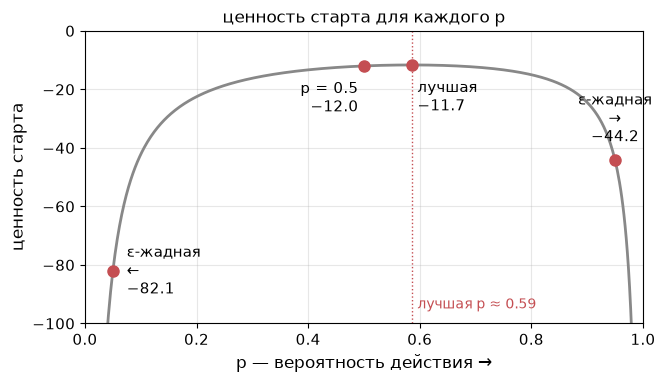

In [6]:
options = {"A. всегда →": 1.0, "B. ε-жадная →": 0.95, "C. → и ← поровну": 0.5, "D. всегда ←": 0.0}
for name, p in options.items():
    v = corridor_value(p)
    print(f"{name:22s} p = {p:4.2f}:  ", f"ценность старта {v:6.1f}" if np.isfinite(v) else "выхода нет никогда")

ps = np.linspace(0.001, 0.999, 9981)
values = np.array([corridor_value(p) for p in ps])
p_best = ps[values.argmax()]
print(f"{'лучшая':22s} p = {p_best:.3f}: ценность старта {values.max():6.2f}   (2 − √2 = {2 - np.sqrt(2):.3f})")

plot_value_curve({"ε-жадная\n→": 0.95, "ε-жадная\n←": 0.05, "p = 0.5": 0.5, "лучшая": p_best},
                 title="ценность старта для каждого p")
plt.show()

Ответ **C**: при $p = 0.5$ агент тратит в среднем 12 шагов (ценность $-12$), с $\varepsilon$-жадной стратегией — 44, почти вчетверо больше. Стратегии «всегда →» и «всегда ←» не доходят до выхода никогда. Лучшая стратегия — $p = 2 - \sqrt{2} \approx 0.586$, где формула достигает максимума: ценность $-11.66$, лишь немного лучше, чем при $p = 0.5$.

**Почему так выходит.** Действие → из клетки 0 ведёт в клетку 1, а там → возвращает в клетку 0 — агент ходит по кругу без конца. Чтобы выйти, в клетке 1 нужно сделать ←, а в клетках 0 и 2 — →. Клеток агент не различает, поэтому ← в клетке 1 может выпасть только случайно. У $\varepsilon$-жадной стратегии ← выпадает 1 раз из 20, и каждая неудача стоит двух шагов — в клетку 0 и обратно: около $20 \cdot 2 = 40$ шагов только на клетку 1, отсюда $-44$. Стратегия $p = 0.5$ в клетке 1 угадывает в половине случаев, зато чаще ошибается в клетках 0 и 2; лучший баланс — $p \approx 0.59$.

Может ли Q-learning научиться такой стратегии? Проверим. Наблюдение одно, поэтому таблица — две оценки: $Q(\leftarrow)$ и $Q(\rightarrow)$. Учим 1000 эпизодов с $\varepsilon = 0.1$ и $\alpha = 0.1$ — это Q-learning лекции 3 без изменений, только таблица из одной строки.

In [7]:
def q_learning_corridor(n_episodes=1000, eps=0.1, alpha=0.1, seed=0, max_steps=1000):
    # Q-learning лекции 3; наблюдение одно, поэтому таблица — две оценки: Q[0] = ←, Q[1] = →
    rng = np.random.default_rng(seed)
    env, Q = Corridor(), np.zeros(2)
    for _ in range(n_episodes):
        env.reset()
        for _ in range(max_steps):
            a = int(rng.integers(2)) if rng.random() < eps else int(rng.choice(np.flatnonzero(Q == Q.max())))
            _, r, terminated, _, _ = env.step(a)
            Q[a] += alpha * (r + (0.0 if terminated else Q.max()) - Q[a])
            if terminated:
                break
    return Q

for seed in range(3):
    Q = q_learning_corridor(seed=seed)
    print(f"сид {seed}: Q(←) = {Q[0]:6.1f}, Q(→) = {Q[1]:6.1f}  ->  по таблице {'→' if Q[1] > Q[0] else '←'}")

env = Corridor(); env.reset()
steps = 0
while steps < 1000:                       # проверка по таблице: всегда →, не больше 1000 шагов
    _, _, terminated, _, _ = env.step(1); steps += 1
    if terminated:
        break
print(f"проверка по таблице: {'дошёл' if terminated else 'не дошёл'} за {steps} шагов")
print(f"с ε = 0.1 во время проверки (p = 0.95): ценность старта {corridor_value(0.95):.1f}")
print(f"ε, при котором ε-жадная стратегия совпала бы с лучшей: {2 * (1 - p_best):.2f}")

сид 0: Q(←) =  -23.0, Q(→) =  -19.2  ->  по таблице →


сид 1: Q(←) =  -23.1, Q(→) =  -20.8  ->  по таблице →


сид 2: Q(←) =  -24.8, Q(→) =  -21.1  ->  по таблице →
проверка по таблице: не дошёл за 1000 шагов
с ε = 0.1 во время проверки (p = 0.95): ценность старта -44.2
ε, при котором ε-жадная стратегия совпала бы с лучшей: 0.83


На всех трёх запусках у → оценка выше, и по таблице агент ходит по кругу между клетками 0 и 1. Выходит он только благодаря случайным шагам $\varepsilon$-жадности — в среднем за 44 шага.

Почему Q-learning не находит лучшую стратегию. По таблице он в каждой клетке выбирает одно действие — с наибольшим $Q$. Клетки коридора неразличимы, значит, это одно действие на весь коридор. Выбирать → с вероятностью 0.59 таблица ценностей не умеет: случайные шаги в ней даёт только $\varepsilon$, а $\varepsilon$ задаёт человек. Подобрать его руками можно — при $\varepsilon \approx 0.83$ $\varepsilon$-жадная стратегия совпала бы с лучшей, — но это подбор, а не обучение; в среде, где нужная доля случайных шагов своя в каждом месте, руками её не подобрать.

**Одной строкой:** если агент не различает состояния, лучшая стратегия бывает стохастической, а Q-learning по таблице даёт только детерминированную. Нужен метод, который учит саму вероятность $p$.

## 3. Стратегия с параметрами: softmax

Сдвигать вероятности напрямую неудобно: они должны оставаться между 0 и 1 и в сумме давать 1. Поэтому каждому действию $a$ дают **предпочтение** $\theta_a$ — любое число — и превращают предпочтения в вероятности формулой **softmax**:

$$
\pi(a) \;=\; \frac{e^{\theta_a}}{\sum_b e^{\theta_b}} ,
$$

где $a$ — действие, чью вероятность считаем, а сумма в знаменателе идёт по всем действиям $b$. Знаменатель у всех действий общий, поэтому вероятности в сумме дают 1 при любых $\theta$. Пример: три действия и $\theta = (1, 0, 0)$ дают $\pi = \big(\tfrac{e}{e + 2},\ \tfrac{1}{e + 2},\ \tfrac{1}{e + 2}\big) \approx (0.58,\ 0.21,\ 0.21)$.

В коридоре действий два. Если прибавить одно и то же число к обоим предпочтениям, числитель и знаменатель умножатся на одно и то же, и вероятности не изменятся. Поэтому предпочтение действия ← закрепляют нулём, а предпочтение действия → обозначают $\theta$:

$$
p \;=\; \frac{e^{\theta}}{1 + e^{\theta}} .
$$

Одно число $\theta$ задаёт всю стратегию.

In [8]:
print("θ = (1, 0, 0)  ->  π =", softmax([1.0, 0.0, 0.0]).round(2))
for theta in (-3.0, 0.0, 3.0):
    print(f"коридор, θ = {theta:+.0f}  ->  p = {softmax([0.0, theta])[1]:.2f}")

θ = (1, 0, 0)  ->  π = [0.58 0.21 0.21]
коридор, θ = -3  ->  p = 0.05
коридор, θ = +0  ->  p = 0.50
коридор, θ = +3  ->  p = 0.95


Как сделать **сыгранное** действие вероятнее? Сдвинуть предпочтения туда, где $\log \pi(a)$ растёт быстрее всего, — по **градиенту**: вектору производных $\log \pi(a)$ по каждому предпочтению. Посчитаем его для трёх действий, когда сыграли B. Обозначим знаменатель $S = e^{\theta_A} + e^{\theta_B} + e^{\theta_C}$; тогда $\pi(B) = e^{\theta_B} / S$ и

$$
\log \pi(B) \;=\; \theta_B - \log S .
$$

Производная $\log S$ по $\theta_A$ — по школьному правилу $(\log S)' = S' / S$, а из всей суммы $S$ от $\theta_A$ зависит только слагаемое $e^{\theta_A}$: получается $e^{\theta_A} / S = \pi(A)$. Так же по $\theta_B$ и $\theta_C$ получаются $\pi(B)$ и $\pi(C)$. Первое слагаемое $\theta_B$ даёт производную 1 по $\theta_B$ и 0 по остальным. Итого

$$
\frac{\partial \log \pi(B)}{\partial \theta_A} = -\pi(A), \qquad
\frac{\partial \log \pi(B)}{\partial \theta_B} = 1 - \pi(B), \qquad
\frac{\partial \log \pi(B)}{\partial \theta_C} = -\pi(C),
$$

или вектором: $\nabla_\theta \log \pi(B) = (0, 1, 0) - \big(\pi(A), \pi(B), \pi(C)\big)$. Для любого сыгранного действия $a$ то же самое:

$$
\nabla_\theta \log \pi(a) \;=\; \vec e_a - \vec\pi ,
$$

где $\vec e_a$ — вектор с единицей на месте $a$ и нулями на остальных местах, а $\vec\pi = \big(\pi(A), \pi(B), \pi(C)\big)$ — вектор вероятностей всех действий; стрелка напоминает, что это вектор, а не число $\pi$. Шаг $\theta \leftarrow \theta + \alpha\,(\vec e_a - \vec\pi)$ поднимает предпочтение сыгранного действия на $\alpha\,(1 - \pi(a))$ и опускает предпочтение каждого другого действия $b$ на $\alpha\,\pi(b)$.

**Вопрос 3 (голосуем).** Действия A, B, C с вероятностями 0.5, 0.3, 0.2; сыграли B. Делаем шаг $\theta \leftarrow \theta + 0.5\,(\vec e_B - \vec\pi)$, где $\vec e_B - \vec\pi = (0, 1, 0) - (0.5, 0.3, 0.2) = (-0.5,\ +0.7,\ -0.2)$. Какие вероятности вырастут?

* **A.** только у B;
* **B.** у B и у A;
* **C.** у всех трёх;
* **D.** у B вырастет, у A и C не изменится.

e_B − вектор вероятностей: [-0.5  0.7 -0.2]
было:  [0.5 0.3 0.2]
стало: [0.39 0.43 0.18]


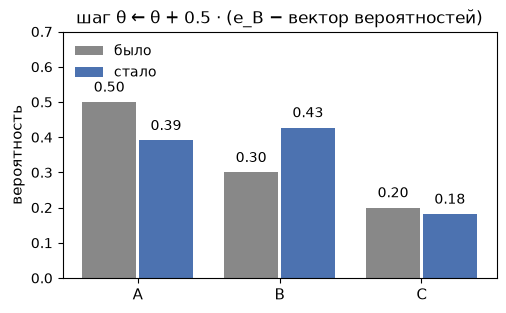

In [9]:
theta = np.log([0.5, 0.3, 0.2])            # такие предпочтения дают вероятности (0.5, 0.3, 0.2)
pi_before = softmax(theta)
grad = np.eye(3)[1] - pi_before            # e_B − вектор вероятностей; B — действие номер 1
pi_after = softmax(theta + 0.5 * grad)
print("e_B − вектор вероятностей:", grad.round(2))
print("было: ", pi_before.round(2))
print("стало:", pi_after.round(2))
plot_probs({"было": pi_before, "стало": pi_after}, labels=["A", "B", "C"], ylim=(0, 0.7),
           title="шаг θ ← θ + 0.5 · (e_B − вектор вероятностей)")
plt.show()

Ответ **A**: B выросла с 0.30 до 0.43, A упала с 0.50 до 0.39, C — с 0.20 до 0.18.

В коридоре предпочтение одно — $\theta$ у действия →, и та же формула даёт: $\nabla_\theta \log \pi(a) = 1 - p$, если сделан шаг →, и $-p$, если ←.

**Одной строкой:** шаг по $\vec e_a - \vec\pi$ делает сыгранное действие вероятнее, а остальные — реже.

## 4. REINFORCE: градиент стратегии по сыгранным эпизодам

Задача: сдвигать предпочтения $\theta$ так, чтобы росла ценность старта $J(\theta)$ — средний return эпизода. Будь у агента формула $J(\theta)$, как у нас для коридора в разделе 2, он шёл бы по её градиенту. Но формулы у агента нет: он только играет эпизоды. Покажем, что градиент можно оценить по одним сыгранным эпизодам.

**Эпизод** — последовательность состояний, действий и наград от старта до конца:

$$
\tau \;=\; (s_0,\, a_0,\, r_0,\; s_1,\, a_1,\, r_1,\; \dots,\; s_{T-1},\, a_{T-1},\, r_{T-1},\; s_T) ,
$$

где $T$ — длина эпизода, $s_T$ — состояние, в котором эпизод закончился. Его return, как в лекции 1, — $G(\tau) = \sum_{t=0}^{T-1} \gamma^t r_t$. Обозначим $\rho_\theta(\tau)$ вероятность сыграть именно этот эпизод при предпочтениях $\theta$. Ценность старта — средний return:

$$
J(\theta) \;=\; \sum_\tau \rho_\theta(\tau)\, G(\tau) \;=\; \mathbb{E}_{\tau \sim \rho_\theta}\big[\, G(\tau) \,\big] .
$$

От $\theta$ здесь зависит только $\rho_\theta(\tau)$. Производная логарифма, как в разделе 3, даёт $\nabla \rho = \rho\, \nabla \log \rho$, поэтому

$$
\begin{aligned}
\nabla_\theta J \;&=\; \sum_\tau G(\tau)\, \nabla_\theta \rho_\theta(\tau) \;=\; \sum_\tau \rho_\theta(\tau)\, G(\tau)\, \nabla_\theta \log \rho_\theta(\tau) \\
&=\; \mathbb{E}_{\tau \sim \rho_\theta}\big[\, G(\tau)\, \nabla_\theta \log \rho_\theta(\tau) \,\big] .
\end{aligned}
$$

Осталось посчитать $\nabla_\theta \log \rho_\theta(\tau)$. Вероятность эпизода — произведение вероятностей его шагов:

$$
\rho_\theta(\tau) \;=\; P(s_0) \prod_{t=0}^{T-1} \pi_\theta(a_t \mid s_t)\, P(s_{t+1} \mid s_t, a_t) ,
$$

где $P(s_0)$ — вероятность стартового состояния, $\pi_\theta(a_t \mid s_t)$ — выбор действия стратегией, $P(s_{t+1} \mid s_t, a_t)$ — переход среды (награду, как и переход, задаёт среда). Логарифм произведения — сумма логарифмов:

$$
\log \rho_\theta(\tau) \;=\; \log P(s_0) \;+\; \sum_{t=0}^{T-1} \log \pi_\theta(a_t \mid s_t) \;+\; \sum_{t=0}^{T-1} \log P(s_{t+1} \mid s_t, a_t) .
$$

Первое и третье слагаемые задаёт среда, от $\theta$ они не зависят:

$$
\begin{aligned}
\nabla_\theta \log \rho_\theta(\tau) \;&=\; \underbrace{\nabla_\theta \log P(s_0)}_{=\,0} \;+\; \sum_{t=0}^{T-1} \nabla_\theta \log \pi_\theta(a_t \mid s_t) \;+\; \underbrace{\sum_{t=0}^{T-1} \nabla_\theta \log P(s_{t+1} \mid s_t, a_t)}_{=\,0} \\
&=\; \sum_{t=0}^{T-1} \nabla_\theta \log \pi_\theta(a_t \mid s_t) .
\end{aligned}
$$

Получилась **теорема о градиенте стратегии** (policy gradient theorem):

$$
\nabla_\theta J \;=\; \mathbb{E}_{\tau \sim \rho_\theta}\Big[\, G(\tau) \sum_{t=0}^{T-1} \nabla_\theta \log \pi_\theta(a_t \mid s_t) \Big] .
$$

Значит, один сыгранный эпизод даёт оценку градиента, в среднем равную точному градиенту:

$$
\widehat{\nabla J} \;=\; G(\tau) \sum_{t=0}^{T-1} \nabla_\theta \log \pi_\theta(a_t \mid s_t) , \qquad \mathbb{E}\big[\widehat{\nabla J}\big] \;=\; \nabla_\theta J .
$$

Шаг по ней поднимает вероятности действий эпизода тем сильнее, чем больше его return. Cross-Entropy из лекции 1 тоже делал чаще действия из сыгранных эпизодов, но брал только элитные эпизоды и все одинаково. Это та же оценка, только вместо return $G(\tau)$ стоит число $w(\tau)$:

$$
\widehat{\nabla J}_{\text{CE}} \;=\; w(\tau) \sum_{t=0}^{T-1} \nabla_\theta \log \pi_\theta(a_t \mid s_t) ,
$$

где $w(\tau) = 1$, если эпизод элитный, и $w(\tau) = 0$, если нет.

На практике вес каждого действия уточняют: действие на шаге $t$ не может повлиять на награды, полученные до него, поэтому их из его веса убирают и оставляют награды с шага $t$ до конца. От $G(\tau) = \sum_k \gamma^k r_k$ остаётся

$$
\sum_{k=t}^{T-1} \gamma^k r_k \;=\; \gamma^t \sum_{k=t}^{T-1} \gamma^{k-t}\, r_k \;=\; \gamma^t\, G_t , \qquad\text{и}\qquad \widehat{\nabla J} \;=\; \sum_{t=0}^{T-1} \gamma^t\, G_t\, \nabla_\theta \log \pi_\theta(a_t \mid s_t) .
$$

Среднее оценки от этого не меняется (почему — в разделе 5), а шума становится меньше.

Алгоритм **REINFORCE** (Уильямс, 1992) после каждого эпизода делает шаг $\theta \leftarrow \theta + \alpha\, \widehat{\nabla J}$.

В коридоре $\gamma = 1$, поэтому $\gamma^t = 1$, а $G_t$ — сумма наград с шага $t$ до конца эпизода. $\nabla_\theta \log \pi(a_t)$ равно $1 - p$, если на шаге $t$ сделан шаг →, и $-p$, если ← (раздел 3). Напишем две функции: `play(theta, rng)` играет эпизод стратегией с вероятностью → $p = e^{\theta} / (1 + e^{\theta})$ и возвращает действия и награды, `grad_estimate(theta, actions, rewards)` считает $\widehat{\nabla J}$. Проверим теорему числом: среднее оценок по 2000 эпизодам должно совпасть с точным наклоном кривой ценности из раздела 2. Точный наклон даёт функция `corridor_slope(theta)` из `pg_plots.py`.

In [10]:
def play(theta, rng, max_steps=1000):
    # эпизод в коридоре: → с вероятностью p = softmax([0, θ])[1]; возвращает действия (1 = →) и награды
    env, p = Corridor(), softmax([0.0, theta])[1]
    env.reset()
    actions, rewards = [], []
    for _ in range(max_steps):
        a = int(rng.random() < p)
        _, r, terminated, _, _ = env.step(a)
        actions.append(a); rewards.append(r)
        if terminated:
            break
    return np.array(actions), np.array(rewards)

def grad_estimate(theta, actions, rewards):
    # Σ_t G_t · ∇ log π(a_t); G_t — сумма наград с шага t до конца, ∇ log π(a_t) = 1 − p при →, −p при ←
    p = softmax([0.0, theta])[1]
    G = np.cumsum(rewards[::-1])[::-1]
    return np.sum(G * (actions - p))

rng = np.random.default_rng(0)
for theta in (-3.0, 0.0, 1.0):
    g = np.array([grad_estimate(theta, *play(theta, rng)) for _ in range(2000)])
    print(f"θ = {theta:+.0f} (p = {softmax([0.0, theta])[1]:.2f}): наклон кривой {corridor_slope(theta):+6.1f}, "
          f"среднее 2000 оценок {g.mean():+6.1f}, разброс одной оценки ±{g.std():.0f}")

θ = -3 (p = 0.05): наклон кривой  +80.2, среднее 2000 оценок  +83.3, разброс одной оценки ±251
θ = +0 (p = 0.50): наклон кривой   +2.0, среднее 2000 оценок   +2.2, разброс одной оценки ±29
θ = +1 (p = 0.73): наклон кривой   -4.0, среднее 2000 оценок   -3.8, разброс одной оценки ±26


Среднее оценок совпадает с наклоном кривой с точностью до шума, а одна оценка разбросана на десятки и сотни единиц. Поэтому шаг берём маленьким.

Осталось собрать алгоритм: функция `reinforce` после каждого эпизода делает шаг $\theta \leftarrow \theta + \alpha \cdot$ `grad_estimate` и запоминает $p$ перед эпизодом. Запустим её десять раз с разными сидами.

**Вопрос 4 (голосуем).** Запускаем REINFORCE из $\theta = -3$: $p = 0.05$, ценность старта $-86$. Шаг $\alpha = 0.001$, 1000 эпизодов. Где окажется $p$?

* **A.** около 1 — ведь → чаще ведёт к выходу;
* **B.** около 0.95;
* **C.** около 0.59;
* **D.** около 0.5.

p после 1000 эпизодов, 10 запусков: [0.5  0.52 0.53 0.55 0.57 0.59 0.6  0.61 0.62 0.65]
ценность старта в конце: от -12.0 до -11.7   (лучшая -11.66)
эпизодов до ценности выше −13: [42, 97, 130, 132, 138, 145, 160, 196, 238, 298]


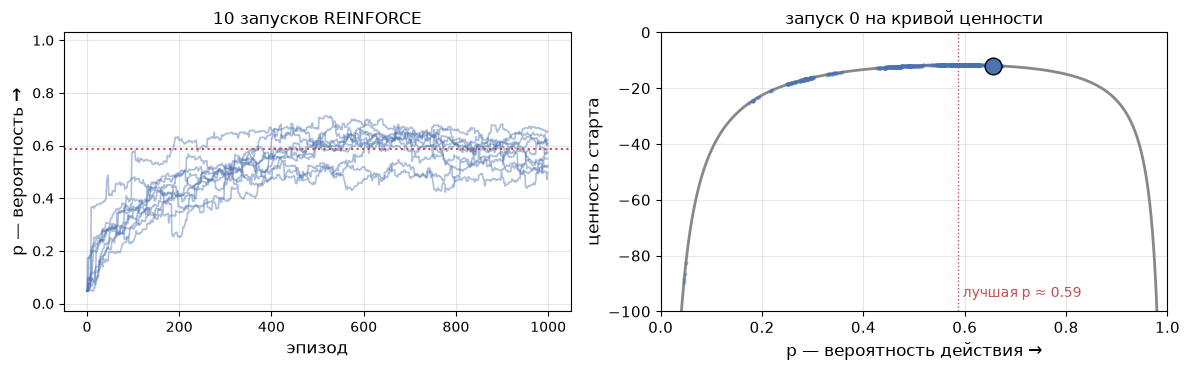

шаг α = 0.01: в 5 из 10 запусков p ушло к 0 или 1


In [11]:
def reinforce(theta=-3.0, alpha=0.001, n_episodes=1000, seed=0):
    # REINFORCE в коридоре; возвращает p перед каждым эпизодом
    rng = np.random.default_rng(seed)
    history = []
    for _ in range(n_episodes):
        history.append(softmax([0.0, theta])[1])
        actions, rewards = play(theta, rng)
        theta += alpha * grad_estimate(theta, actions, rewards)
    return np.array(history)

runs = np.array([reinforce(seed=s) for s in range(10)])
final = runs[:, -1]
reached = [int(np.argmax([corridor_value(p) > -13 for p in run])) for run in runs]
print("p после 1000 эпизодов, 10 запусков:", np.sort(final).round(2))
print(f"ценность старта в конце: от {min(map(corridor_value, final)):.1f} до {max(map(corridor_value, final)):.1f}"
      f"   (лучшая {corridor_value(p_best):.2f})")
print("эпизодов до ценности выше −13:", sorted(reached))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_seeds(runs, ax=axes[0], ylabel="p — вероятность →", xlabel="эпизод", title="10 запусков REINFORCE")
axes[0].axhline(p_best, color=C_ACCENT, ls=":", lw=1.5)
plot_value_curve(ax=axes[1], trail=runs[0], marker=runs[0, -1], title="запуск 0 на кривой ценности")
plt.tight_layout(); plt.show()

big_step = np.array([reinforce(alpha=0.01, seed=s)[-1] for s in range(10)])
stuck = int(np.sum((big_step < 0.01) | (big_step > 0.99)))
print(f"шаг α = 0.01: в {stuck} из 10 запусков p ушло к 0 или 1")

Ответ **C**: все десять запусков пришли к вершине кривой — $p$ от 0.50 до 0.65, ценность старта от $-12.0$ до $-11.7$ при лучшей $-11.66$. Это стохастическая стратегия, которую Q-learning по таблице дать не может. Вот как запуск 0 идёт по кривой ценности:

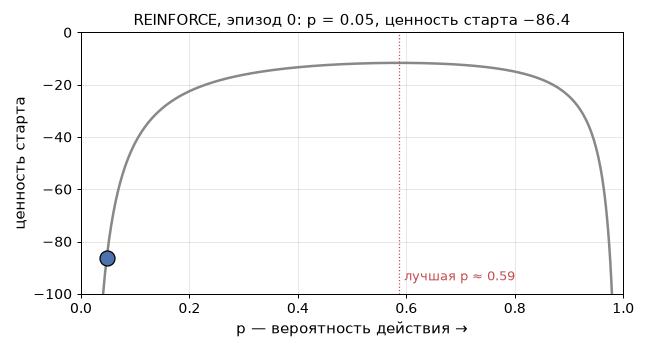

**Почему так выходит.** Средний шаг REINFORCE — наклон кривой ценности: это мы только что проверили числом. Слева от вершины кривая растёт — и $p$ увеличивается; справа падает — и $p$ уменьшается; в вершине наклон равен нулю, там $p$ и останавливается. Вершина пологая: при $p$ от 0.50 до 0.65 ценность хуже лучшей меньше чем на полшага, поэтому шум отдельных эпизодов и разносит запуски вдоль неё. Ответ A — ловушка: действие → действительно нужно чаще, но не всегда.

С шагом $\alpha = 0.01$ сорвалась половина запусков — 5 из 10: шумная оценка одного длинного эпизода выбросила $p$ к 0 или к 1, где выхода нет, и обучение остановилось. К выбору шага мы вернёмся в теме PPO.

**Одной строкой:** REINFORCE после каждого эпизода сдвигает $\theta$ на $\alpha \sum_t G_t \nabla \log \pi(a_t \mid s_t)$; в коридоре он находит лучшую стохастическую стратегию $p \approx 0.59$.

## 5. Вычитаем среднее

**Задача: три игровых автомата.** За одну попытку агент выбирает один из трёх автоматов и получает случайный выигрыш. Автомат №1 выигрывает в среднем +101, №2 — +102, №3 — +103, каждый раз с отклонением около 1. Средних агент не знает. Лучший — №3, но разница между автоматами всего 1, а сам выигрыш около 100. Состояние одно, эпизод — одна попытка, return — выигрыш $R$. Стратегия — softmax по трём предпочтениям, шаг REINFORCE после попытки — $\theta \leftarrow \theta + \alpha\, R\, (\vec e_a - \vec\pi)$, где $a$ — сыгранный автомат.

**Вопрос 5 (голосуем).** Вероятности равные, сыграли худший автомат №1 и выиграли +101. Что шаг REINFORCE с $\alpha = 0.01$ сделает с вероятностью автомата №1?

* **A.** вырастет;
* **B.** упадёт;
* **C.** не изменится;
* **D.** зависит от $\alpha$.

было:  [0.33 0.33 0.33]
стало: [0.58 0.21 0.21]


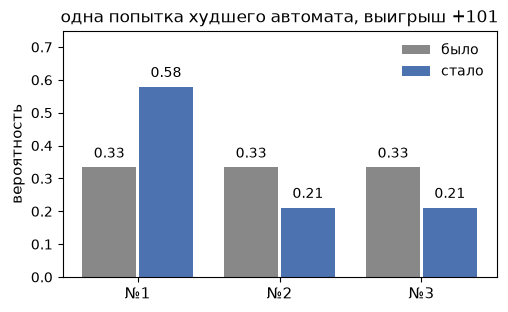

In [12]:
means = np.array(BANDIT_MEANS) + 100                 # средние выигрыши автоматов №1, №2, №3: 101, 102, 103
labels = ["№1", "№2", "№3"]
theta0 = np.zeros(3); pi0 = softmax(theta0)          # равные вероятности
a, R, alpha = 0, 101.0, 0.01                         # сыграли автомат №1, выиграли +101
theta_new = theta0 + alpha * R * (np.eye(3)[a] - pi0)
print("было: ", pi0.round(2))
print("стало:", softmax(theta_new).round(2))
plot_probs({"было": pi0, "стало": softmax(theta_new)}, labels=labels, ylim=(0, 0.75), legend_loc="upper right",
           title="одна попытка худшего автомата, выигрыш +101")
plt.show()

Ответ **A**: вероятность худшего автомата выросла с 0.33 до 0.58.

**Почему.** Шаг сдвигает предпочтение сыгранного автомата на $\alpha \cdot R \cdot (1 - \pi(\text{№1})) = 0.01 \cdot 101 \cdot 0.67 \approx 0.67$, каким бы автомат ни был: $R$ всегда около 100. Разница между автоматами — единица выигрыша — меняет этот сдвиг всего на $0.01 \cdot 1 \cdot 0.67 \approx 0.007$, в сто раз меньше. Поэтому вперёд вырывается автомат, который случайно сыграли первым. Его играют чаще, и его вероятность растёт дальше.

**Как это исправить: вычитать среднее.** Вес попытки — не $R$, а $R - b$, где $b$ — средний выигрыш всех попыток до сих пор. Когда $b \approx 102$:

* у №1 вес $101 - 102 = -1$, и его вероятность падает;
* у №3 вес $+1$, и его вероятность растёт.

Сдвигов на 0.67 больше нет, остаётся только разница между автоматами.

Проверим опытом: 20 запусков по 2000 попыток с $\alpha = 0.01$, без вычитания и с ним (`baseline=True`). Для сравнения — те же автоматы без +100, со средними 1, 2, 3.

выигрыши 1 / 2 / 3:                        закрепились на №1 / №2 / №3:  0 /  0 / 20
выигрыши 101 / 102 / 103:                  закрепились на №1 / №2 / №3:  8 /  7 /  5
выигрыши 101 / 102 / 103, вычитаем среднее: закрепились на №1 / №2 / №3:  0 /  0 / 20


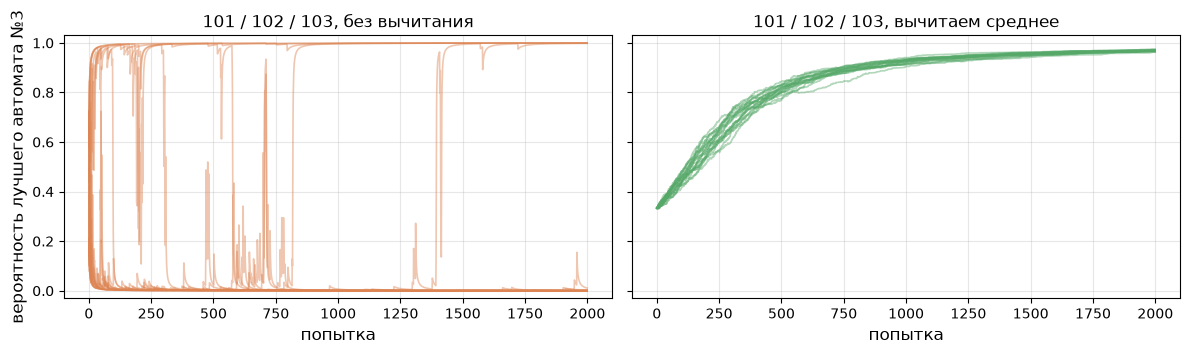

In [13]:
def bandit_reinforce(means, alpha=0.01, n_steps=2000, seed=0, baseline=False):
    # REINFORCE на автоматах; возвращает вероятности всех автоматов после каждой попытки: массив (n_steps, 3)
    rng = np.random.default_rng(seed)
    theta, b, history = np.zeros(len(means)), 0.0, []
    for n in range(1, n_steps + 1):
        pi = softmax(theta)
        a = rng.choice(len(means), p=pi)
        R = rng.normal(means[a], 1.0)
        b += (R - b) / n                             # среднее на ходу (лекция 3): средний выигрыш всех попыток
        weight = R - b if baseline else R
        theta += alpha * weight * (np.eye(len(means))[a] - pi)
        history.append(softmax(theta))
    return np.array(history)

def summary(runs):
    # runs — массив (запуски, попытки, 3): на каком автомате закрепился каждый запуск (наибольшая вероятность в конце)
    winners = np.bincount(runs[:, -1].argmax(axis=1), minlength=3)
    return f"закрепились на №1 / №2 / №3: {winners[0]:2d} / {winners[1]:2d} / {winners[2]:2d}"

plain = np.array([bandit_reinforce(means - 100, seed=s) for s in range(20)])
shifted = np.array([bandit_reinforce(means, seed=s) for s in range(20)])
centered = np.array([bandit_reinforce(means, seed=s, baseline=True) for s in range(20)])
print("выигрыши 1 / 2 / 3:                       ", summary(plain))
print("выигрыши 101 / 102 / 103:                 ", summary(shifted))
print("выигрыши 101 / 102 / 103, вычитаем среднее:", summary(centered))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
plot_seeds(shifted[:, :, 2], ax=axes[0], color=C_REWARD, ylabel="вероятность лучшего автомата №3",
           title="101 / 102 / 103, без вычитания")
plot_seeds(centered[:, :, 2], ax=axes[1], color=C_ENV, title="101 / 102 / 103, вычитаем среднее")
plt.tight_layout(); plt.show()

Без +100 все 20 запусков находят лучший автомат. С +100 без вычитания его находят только 5 из 20, а 8 закрепляются на **худшем** №1. С вычитанием — снова все 20, как будто +100 не было.

Средний шаг вычитание не меняет. Для числа $b$, не зависящего от выбора действия:

$$
\mathbb{E}_{a \sim \pi}\big[\, b\, \nabla \log \pi(a) \,\big] \;=\; b \sum_a \pi(a)\, \nabla \log \pi(a) \;=\; b \sum_a \nabla \pi(a) \;=\; b\, \nabla 1 \;=\; 0 .
$$

В эпизодах вес действия $a_t$ — $\gamma^t (G_t - b)$. Тот же довод объясняет переход к $G_t$ в разделе 4: награды до шага $t$ от выбора $a_t$ не зависят, для него это такое же число $b$.

То же вычитание встретится в CartPole (награда +1 за каждый шаг — тот же случай, проверим на семинаре), в actor-critic ($b = V(s)$, неделя 9) и в GRPO для языковых моделей.

**Одной строкой:** вычитай из выигрыша средний — средний шаг тот же, а случайные скачки исчезают.

## 6. ⏱ Value-based или policy-based

| | value-based (Q-learning, SARSA) | policy-based (REINFORCE) |
|---|---|---|
| что учим | ценности $Q(s,a)$ | вероятности $\pi(a \mid s)$ через предпочтения $\theta$ |
| какая стратегия получается | детерминированная: действие с наибольшим $Q$ | любая — и детерминированная, и стохастическая |
| лучшая стратегия стохастическая (коридор) | по таблице её не получить | находит, $p \approx 0.59$ |
| непрерывные действия (усилие в суставе робота) | на каждом шаге нужен $\max_a Q(s,a)$ по непрерывному $a$ — отдельная задача оптимизации | стратегия выдаёт распределение действий, например нормальное: среднее и разброс |
| чьи данные | Q-learning учится и по чужому логу (off-policy, лекция 4) | только свежие эпизоды своей стратегии (on-policy): после шага старые эпизоды — уже про другую стратегию |
| когда учится | на каждом шаге (TD) | после конца эпизода, оценка шумная |

Дальше в курсе эти семьи сойдутся: actor-critic берёт у policy-based саму стратегию, а у value-based — оценку ценности, которую вычитает как $b$.

**Одной строкой:** policy-based методы выражают любые стратегии и непрерывные действия, но платят шумом и on-policy данными.

## 7. Итоги и где это работает

1. **Две семьи методов.** Value-based учат ценности и выбирают действие с наибольшей — стратегия детерминированная; policy-based учат сами вероятности действий — стратегия стохастическая.
2. **Лучшая стратегия бывает стохастической.** В коридоре, где агент не различает клеток, ценность старта $V(0) = -2(2 - p)/(p(1 - p))$: стратегия $p = 0.5$ набирает $-12$, $\varepsilon$-жадная стратегия — $-44$, детерминированная не доходит до выхода никогда.
3. **Теорема о градиенте стратегии:** $\nabla J = \mathbb{E}\big[G \sum_t \nabla \log \pi(a_t \mid s_t)\big]$ — градиент оценивается по сыгранным эпизодам; для softmax $\nabla \log \pi(a) = \vec e_a - \vec\pi$.
4. **REINFORCE**: после эпизода $\theta \leftarrow \theta + \alpha \sum_t \gamma^t\, G_t\, \nabla \log \pi(a_t \mid s_t)$, где $G_t = \sum_{k \ge t} \gamma^{k-t} r_k$ — дисконтированные награды с шага $t$ до конца. В коридоре ($\gamma = 1$) он находит $p \approx 0.59$.
5. **Вычитай среднее.** Вес $R - b$ не меняет средний шаг, но убирает разброс: при наградах около +100 без вычитания REINFORCE закрепляется на случайном автомате, с вычитанием находит лучший.

**Где это работает в жизни.**

* **Языковые модели.** Дообучение по оценкам ответов — градиент стратегии: стратегия — модель, действие — следующий токен, награда — оценка ответа. В методе GRPO вычитание среднего по ответам на один вопрос — ровно наш раздел 5.
* **Роботы.** Ходьба и манипуляция — непрерывные действия; стратегия выдаёт распределение усилий, и учат её методами этой семьи (PPO, неделя 10).
* **Игры.** В AlphaGo сеть-стратегию дообучали градиентом стратегии на партиях против её же прежних версий.

Словарь лекции: **value-based, policy-based, стратегия с параметрами, предпочтения $\theta$, softmax, градиент стратегии, $\nabla \log \pi$, теорема о градиенте стратегии, REINFORCE, $G_t$ (награды до конца эпизода), вычитание среднего (baseline)**.

## Литература

* Саттон Р., Барто Э. *Обучение с подкреплением*, 2-е изд., глава 13 «Policy Gradient Methods»; коридор — пример 13.1. [incompleteideas.net/book/the-book-2nd.html](http://incompleteideas.net/book/the-book-2nd.html)
* Williams R. J. *Simple statistical gradient-following algorithms for connectionist reinforcement learning*. Machine Learning, 1992 — статья, где появился REINFORCE.
* OpenAI Spinning Up, «Intro to Policy Optimization» — тот же вывод с кодом на PyTorch: [spinningup.openai.com](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html)
* [Учебник по машинному обучению ШАД, глава «Обучение с подкреплением»](https://education.yandex.ru/handbook/ml/article/obuchenie-s-podkrepleniem) — раздел про policy gradient.

## На семинаре и дома

* **Квиз недели 5** — на [странице квизов](https://ilyachichkanov.github.io/Reinforcement-learning/), в зачётном режиме.
* **Домашка 2** — дедлайн 3 ноября, 23:59 МСК.
* **На семинаре** REINFORCE пишем своими руками и учим им стратегию для CartPole — с вычитанием среднего и без.